In [111]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import timm
import numpy as np
from image_preprocess import prepare_datasets 

# Configuration
DATASET_PATH = 'dataset/aerial_landscapes'
NUM_CLASSES = 15
BATCH_SIZE = 1
SEED = 18
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_FILE = "best_model.pth"

In [112]:
# Set random seed
torch.manual_seed(SEED)

_, test_dataset = prepare_datasets(DATASET_PATH, seed=SEED)
class_names = test_dataset.subset.dataset.classes

def evaluate_model(model_file, test_dataset):
    # Load test set
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    # Load model
    model = timm.create_model('seresnet50', pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(model_file, map_location=DEVICE))
    model.eval().to(DEVICE)

    # Collect predictions
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_preds, all_labels


def plot_confusion_matrix(class_names, all_labels, all_preds, title):
    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 10))
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_accuracy(train_accs, val_accs):
    plt.figure(figsize=(10, 5))
    plt.plot(train_accs, label="Train Accuracy", marker='o')
    plt.plot(val_accs,   label="Validation Accuracy", marker='s')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training & Validation Accuracy over Epochs")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

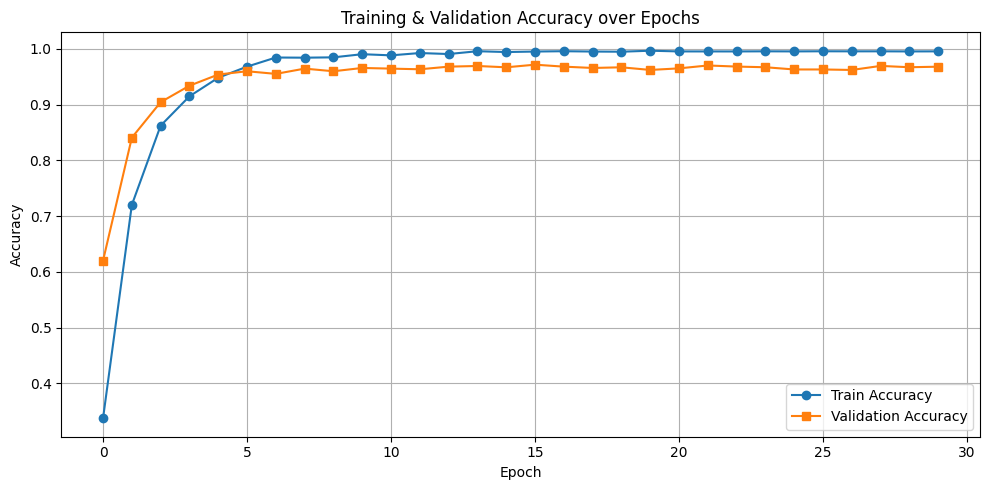

In [113]:
MODEL_FILE = "best_model_longtail_without_any_aug.pth"
train_accs = np.load("train_accs_longtail_without_any_aug.npy")
val_accs = np.load("val_accs_longtail_without_any_aug.npy")
plot_accuracy(train_accs,val_accs)

In [114]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
longtail_without_any_aug_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.958     0.988     0.972       160
     Airport      0.919     0.988     0.952       160
       Beach      0.899     1.000     0.947       160
        City      0.869     0.994     0.927       160
      Desert      0.957     0.975     0.966       160
      Forest      0.957     0.969     0.963       160
   Grassland      0.945     0.969     0.957       160
     Highway      0.969     0.969     0.969       160
        Lake      0.944     0.956     0.950       160
    Mountain      0.917     0.963     0.939       160
     Parking      1.000     0.956     0.978       160
        Port      0.980     0.938     0.958       160
     Railway      0.973     0.906     0.939       160
 Residential      0.993     0.875     0.930       160
       River      0.992     0.787     0.878       160

    accuracy                          0.949      2400
   macro avg      0.951     0.949     0.948      2400
we

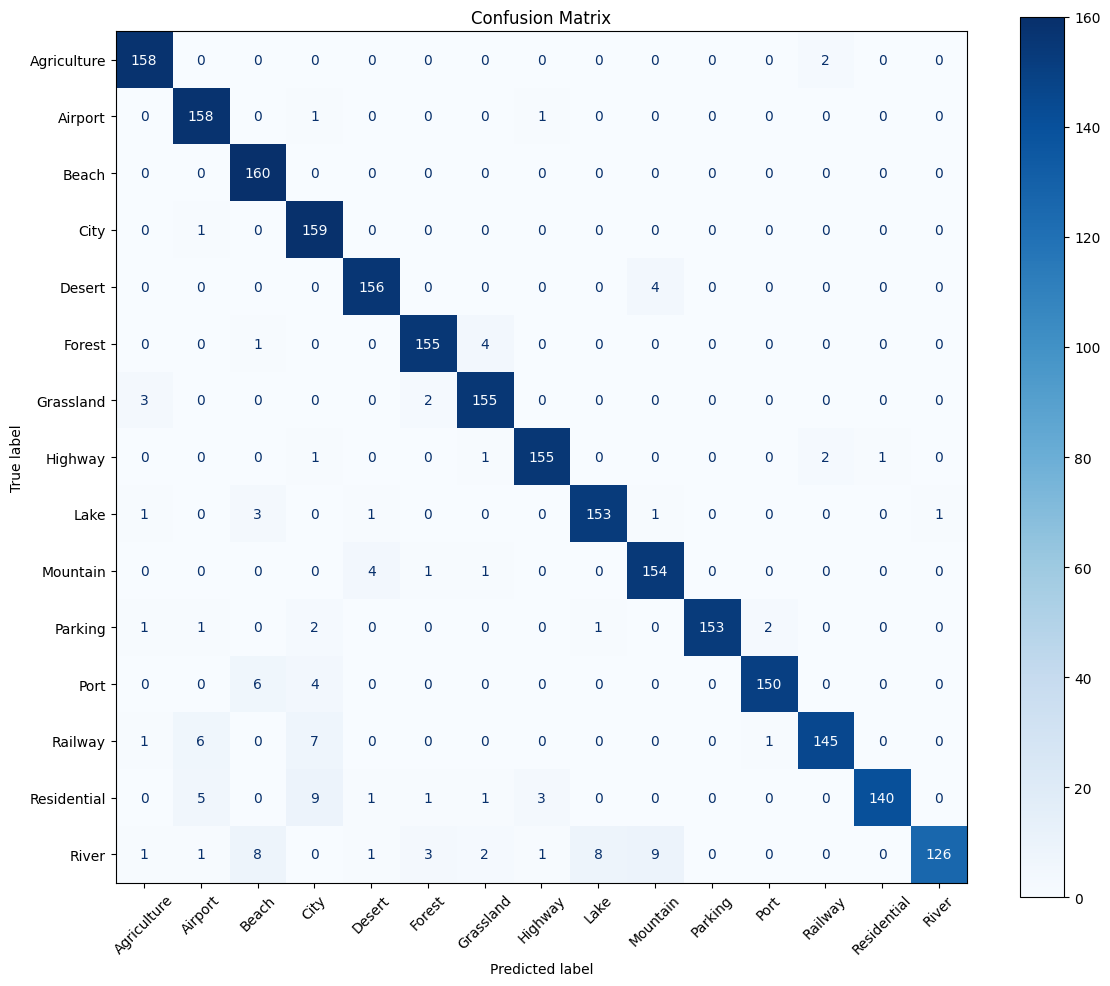

In [115]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

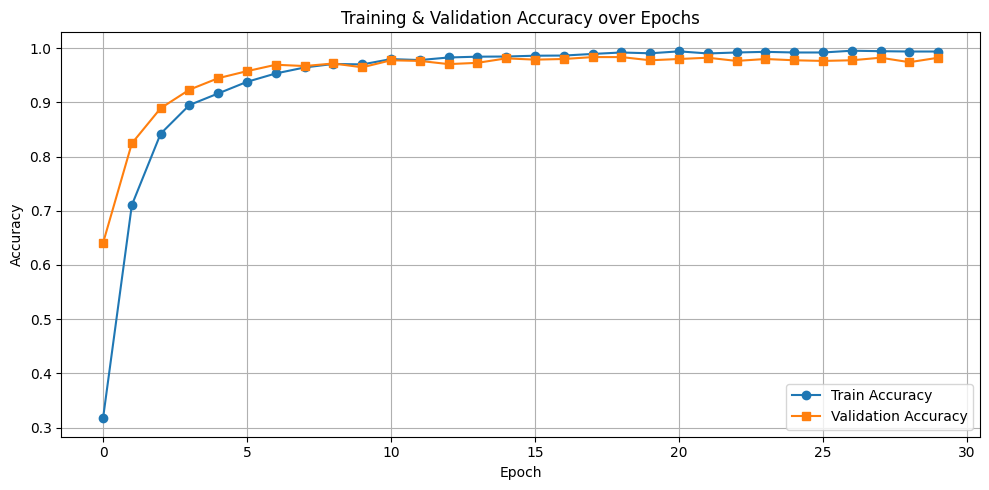

In [116]:
MODEL_FILE = 'best_model_longtail_only_aug_data.pth'
train_accs = np.load("train_accs_longtail_only_aug_data.npy")
val_accs = np.load("val_accs_longtail_only_aug_data.npy")
plot_accuracy(train_accs,val_accs)

In [117]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)
# Classification Report
print("\nClassification Report:")
longtail_only_aug_data_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.976     1.000     0.988       160
     Airport      0.947     1.000     0.973       160
       Beach      0.947     1.000     0.973       160
        City      0.958     1.000     0.979       160
      Desert      0.946     0.994     0.970       160
      Forest      0.963     0.969     0.966       160
   Grassland      0.975     0.969     0.972       160
     Highway      0.964     0.994     0.978       160
        Lake      0.956     0.956     0.956       160
    Mountain      0.968     0.950     0.959       160
     Parking      1.000     0.988     0.994       160
        Port      0.994     0.969     0.981       160
     Railway      1.000     0.938     0.968       160
 Residential      0.987     0.950     0.968       160
       River      0.979     0.875     0.924       160

    accuracy                          0.970      2400
   macro avg      0.971     0.970     0.970      2400
we

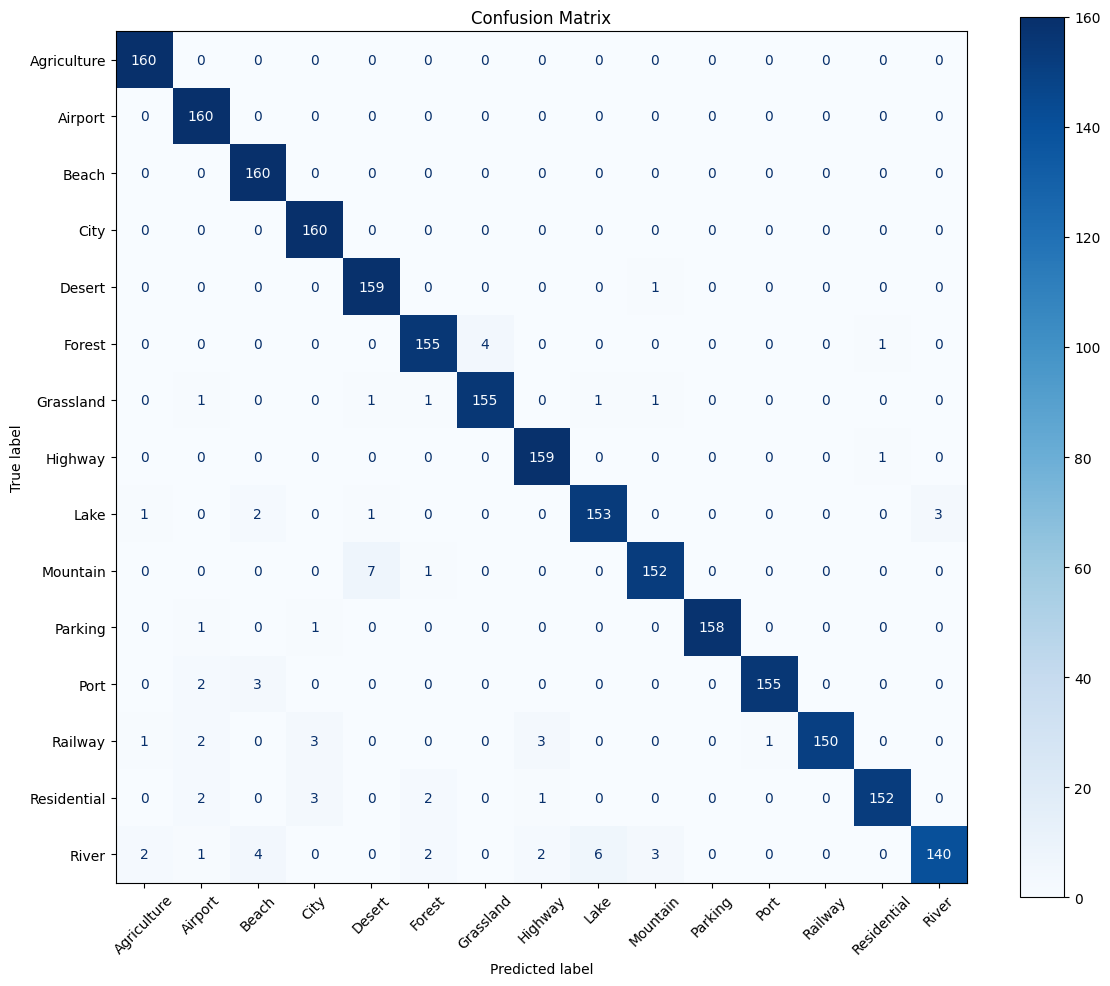

In [118]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

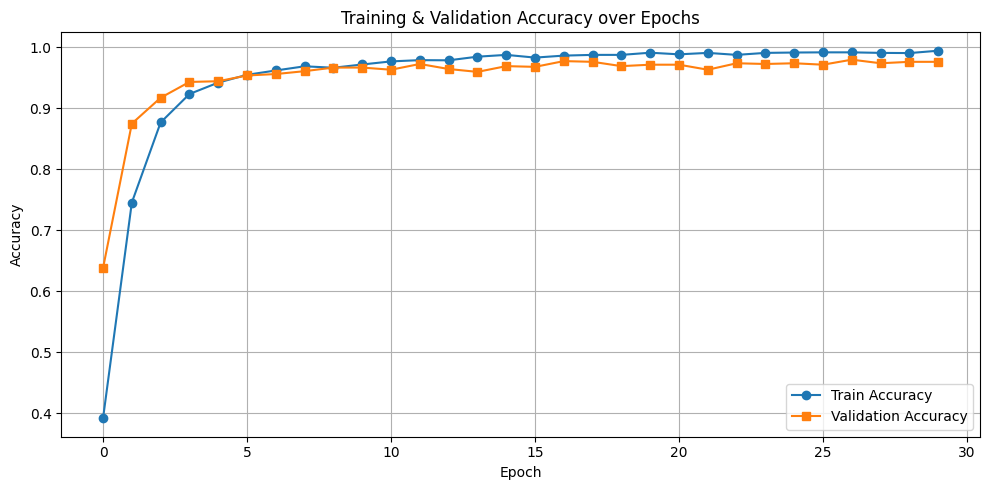

In [119]:
MODEL_FILE = 'best_model_longtail_resampling.pth'
train_accs = np.load("train_accs_longtail_resampling.npy")
val_accs = np.load("val_accs_longtail_resampling.npy")
plot_accuracy(train_accs,val_accs)

In [120]:

all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
longtail_resampling_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.947     1.000     0.973       160
     Airport      0.920     1.000     0.958       160
       Beach      0.964     1.000     0.982       160
        City      0.920     1.000     0.958       160
      Desert      0.981     0.981     0.981       160
      Forest      0.963     0.975     0.969       160
   Grassland      0.981     0.969     0.975       160
     Highway      0.970     1.000     0.985       160
        Lake      0.957     0.963     0.960       160
    Mountain      0.963     0.969     0.966       160
     Parking      0.987     0.963     0.975       160
        Port      0.993     0.950     0.971       160
     Railway      1.000     0.919     0.958       160
 Residential      0.987     0.950     0.968       160
       River      0.993     0.869     0.927       160

    accuracy                          0.967      2400
   macro avg      0.968     0.967     0.967      2400
we

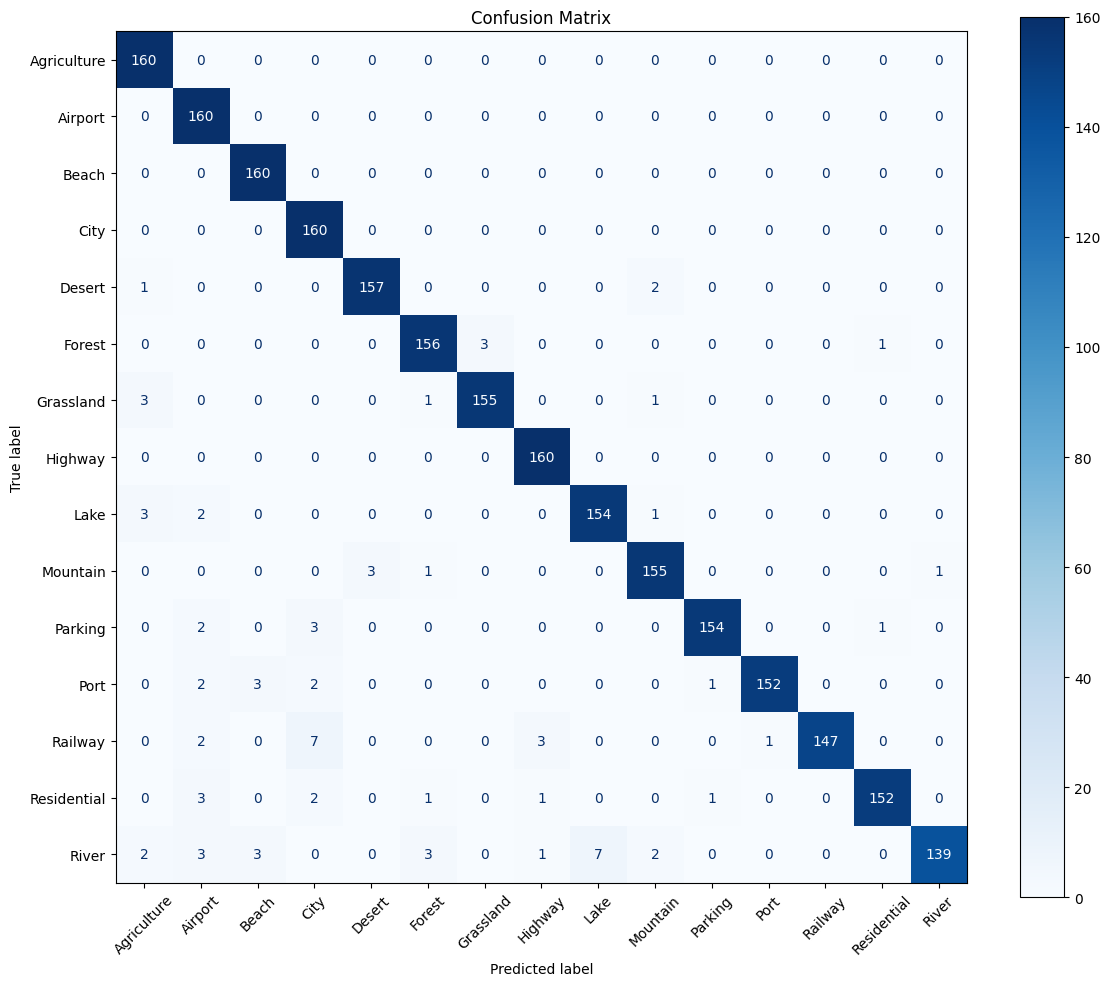

In [121]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

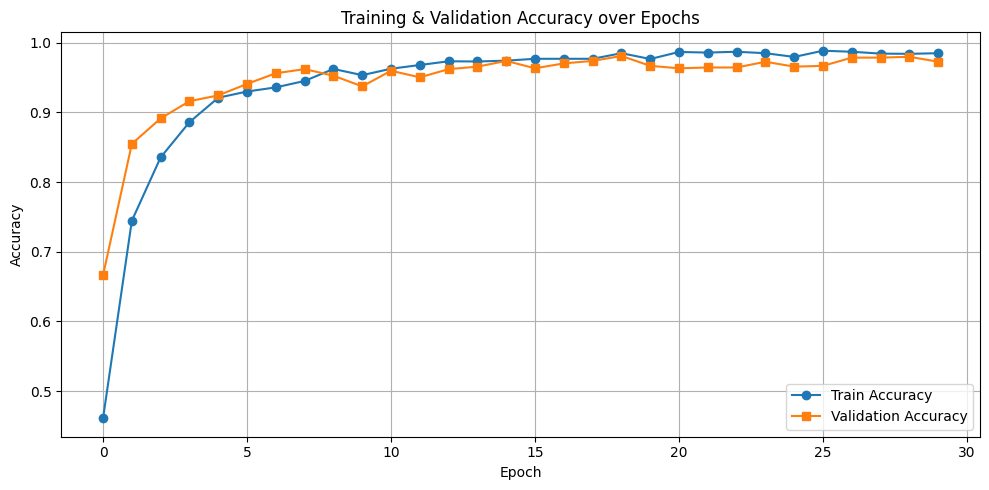

In [122]:
MODEL_FILE = 'best_model_longtail_reweighting.pth'
train_accs = np.load("train_accs_longtail_reweighting.npy")
val_accs = np.load("val_accs_longtail_reweighting.npy")
plot_accuracy(train_accs,val_accs)

In [123]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
longtail_reweighting_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.958     0.994     0.975       160
     Airport      0.957     0.981     0.969       160
       Beach      0.952     1.000     0.976       160
        City      0.919     0.994     0.955       160
      Desert      0.987     0.969     0.978       160
      Forest      0.974     0.938     0.955       160
   Grassland      0.934     0.975     0.954       160
     Highway      0.975     0.981     0.978       160
        Lake      0.945     0.975     0.960       160
    Mountain      0.945     0.963     0.954       160
     Parking      0.969     0.975     0.972       160
        Port      1.000     0.969     0.984       160
     Railway      0.980     0.906     0.942       160
 Residential      0.981     0.963     0.972       160
       River      1.000     0.881     0.937       160

    accuracy                          0.964      2400
   macro avg      0.965     0.964     0.964      2400
we

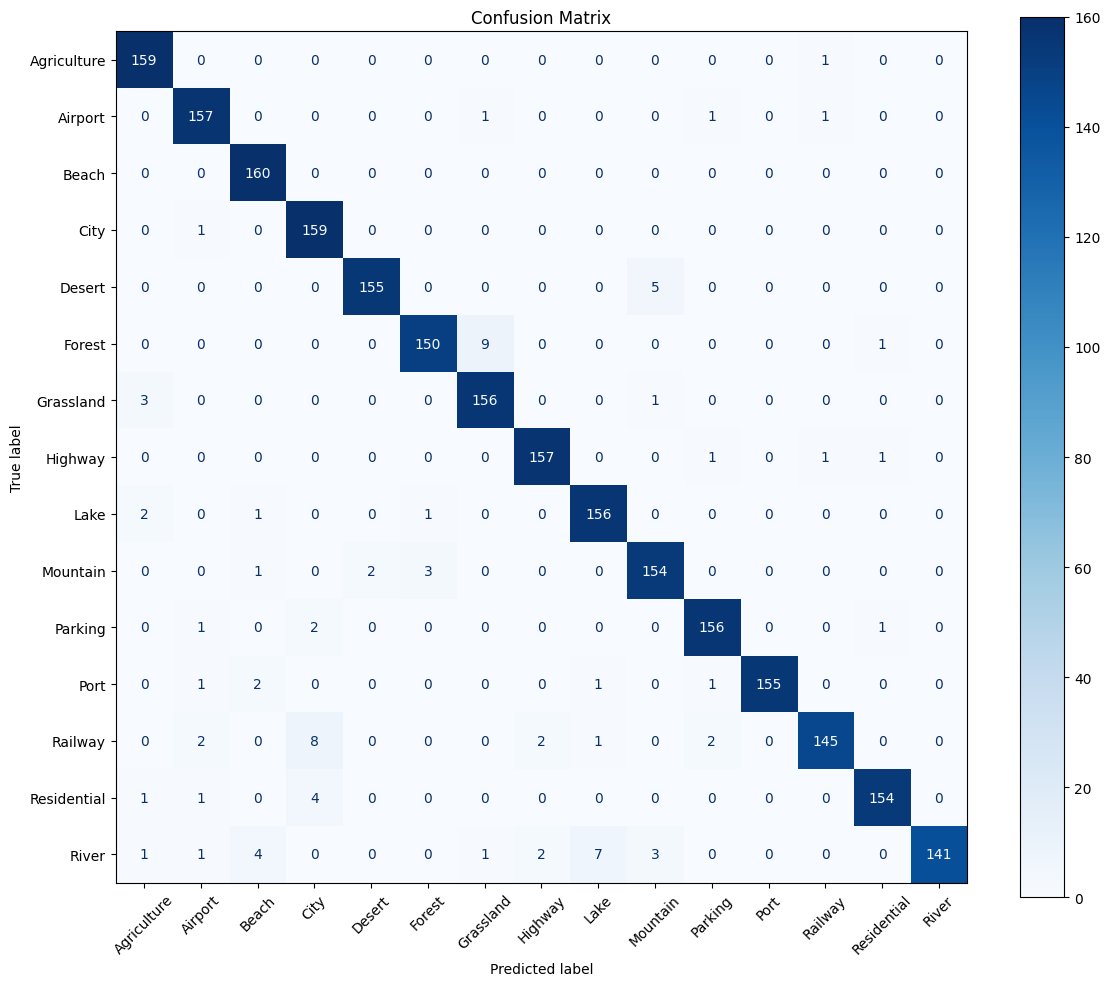

In [124]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

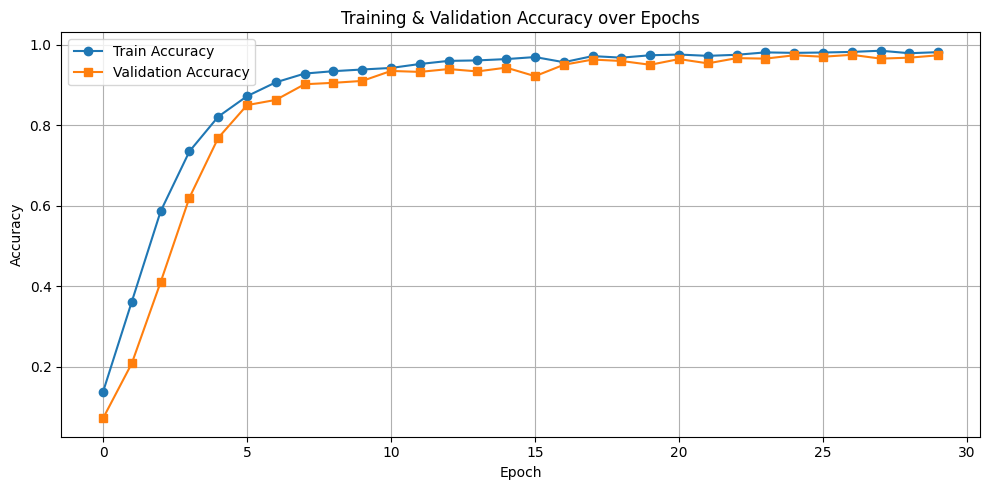

In [125]:
MODEL_FILE = 'best_model_longtail_both.pth'
train_accs = np.load("train_accs_longtail_both.npy")
val_accs = np.load("val_accs_longtail_both.npy")
plot_accuracy(train_accs,val_accs)

In [126]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
longtail_both_process_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.970     0.994     0.981       160
     Airport      0.963     0.981     0.972       160
       Beach      0.981     0.994     0.988       160
        City      0.941     1.000     0.970       160
      Desert      0.981     0.981     0.981       160
      Forest      0.968     0.956     0.962       160
   Grassland      0.951     0.975     0.963       160
     Highway      0.970     0.994     0.981       160
        Lake      0.940     0.988     0.963       160
    Mountain      0.969     0.975     0.972       160
     Parking      1.000     0.981     0.991       160
        Port      0.988     0.988     0.988       160
     Railway      0.980     0.931     0.955       160
 Residential      0.987     0.969     0.978       160
       River      1.000     0.875     0.933       160

    accuracy                          0.972      2400
   macro avg      0.973     0.972     0.972      2400
we

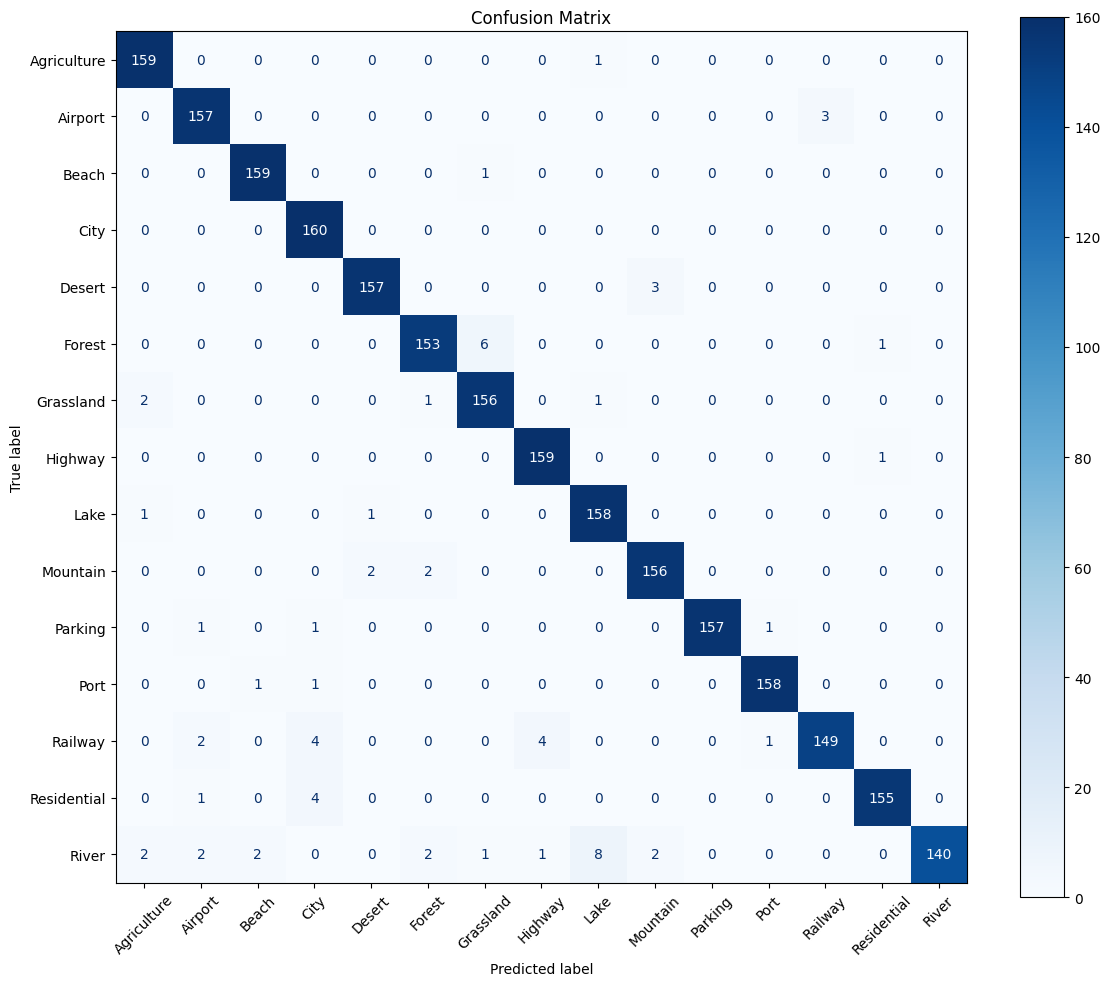

In [127]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

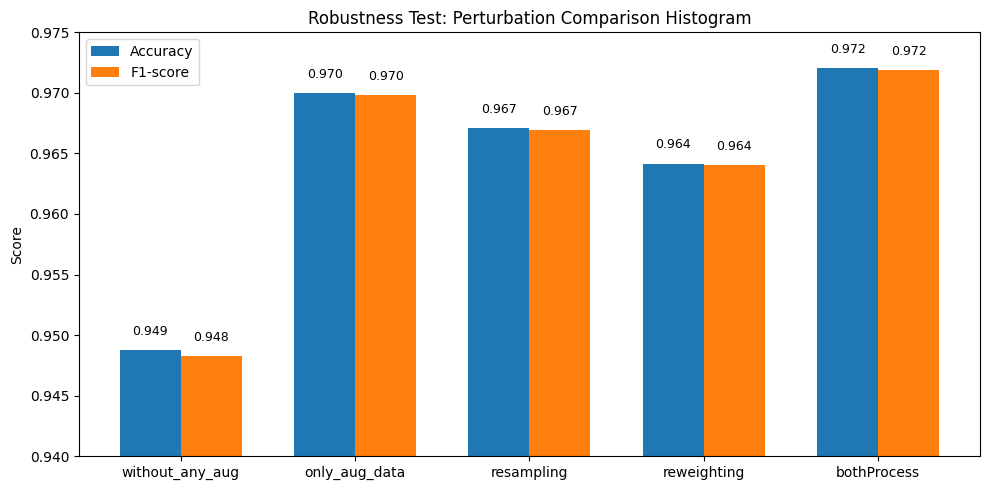

In [128]:
longtail_reports = {
    "without_any_aug": longtail_without_any_aug_classification_report,
    "only_aug_data": longtail_only_aug_data_classification_report,
    "resampling": longtail_resampling_classification_report,
    "reweighting": longtail_reweighting_classification_report,
    "bothProcess": longtail_both_process_classification_report
}

# Prepare data
perturbations = ["without_any_aug", "only_aug_data", "resampling", "reweighting", "bothProcess"]
accuracies = [longtail_reports[p]['accuracy'] for p in perturbations]
f1_scores = [longtail_reports[p]['macro avg']['f1-score'] for p in perturbations]

# Set bar positions
x = range(len(perturbations))
width = 0.35

# Plot
plt.figure(figsize=(10, 5))
plt.bar([i - width/2 for i in x], accuracies, width=width, label='Accuracy')
plt.bar([i + width/2 for i in x], f1_scores, width=width, label='F1-score')

plt.xticks(ticks=x, labels=perturbations)
plt.ylim(0.94, 0.975)
plt.ylabel("Score")
plt.title("Robustness Test: Perturbation Comparison Histogram")
plt.legend()
for i in range(len(perturbations)):
    plt.text(i - width/2, accuracies[i] + 0.001, f"{accuracies[i]:.3f}", ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, f1_scores[i] + 0.001, f"{f1_scores[i]:.3f}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()
